# M3 - Profile before cleaning

**Steam Catalog Trends by Release Year** - profile of the M2 tables (`data/steam_catalog.db`).

This notebook only **reads** the M2 tables (the database is opened read-only). It looks for problems;
it does not answer the project question. Every finding here has an issue ID in
[`docs/cleaning_report.md`](../docs/cleaning_report.md) and a rule in `src/clean.py`.

Run it top to bottom on a fresh build:

```bash
python src/load.py      # builds data/steam_catalog.db from data/raw/
jupyter nbconvert --to notebook --execute --inplace notebooks/m3_profile.ipynb
```

Sections: 1 row counts and coverage · 2 missing values · 3 extremes, modes and sentinels ·
4 distinct values (`repr`) · 5 text and Unicode · 6 identity · 7 values in sequence ·
8 unusual values (robust fences) · 9 rules across fields · 10 findings

In [1]:
import math
import sqlite3
import sys
import unicodedata
import difflib
from collections import Counter, defaultdict
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "sql").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from clean import name_key, normalise_text   # the same key function clean.py uses

DB = ROOT / "data" / "steam_catalog.db"
con = sqlite3.connect(f"{DB.as_uri()}?mode=ro", uri=True)   # read-only: profiling cannot change M2
pd.set_option("display.width", 200, "display.max_colwidth", 60, "display.max_columns", 20)

def q(sql, params=()):
    return pd.read_sql_query(sql, con, params=params)

print("database:", DB.relative_to(ROOT))
print("SQLite", sqlite3.sqlite_version, "| pandas", pd.__version__)

database: data/steam_catalog.db
SQLite 3.53.1 | pandas 3.0.5


## 1. Row counts and coverage

Rows per table, and rows per **release year** - the dimension the project compares. Unequal coverage
makes comparisons between years meaningless, so we need to know how many games each year stands on.

In [2]:
m2_tables = ["app", "app_detail", "review_snapshot", "genre", "category", "developer", "publisher",
             "app_genre", "app_category", "app_developer", "app_publisher", "quarantine"]
counts = {t: con.execute("SELECT COUNT(*) FROM " + t).fetchone()[0] for t in m2_tables}  # static names
pd.Series(counts, name="rows").to_frame()

,rows
app,190242
app_detail,100
review_snapshot,100
genre,12
category,49
developer,107
publisher,101
app_genre,283
app_category,508
app_developer,107


In [3]:
years = q('''
    SELECT COALESCE(substr(release_date, 1, 4), 'no full date') AS release_year,
           COUNT(*) AS games,
           SUM(coming_soon) AS not_released
    FROM app_detail GROUP BY 1 ORDER BY 1''')
print("retrieval runs:", q("SELECT COUNT(DISTINCT substr(retrieved_at,1,10)) AS days, MIN(retrieved_at) AS first, "
                         "MAX(retrieved_at) AS last FROM app_detail").to_string(index=False))
years

retrieval runs:  days                first                 last
    1 2026-10-03T11:38:18Z 2026-10-03T11:42:08Z


,release_year,games,not_released
0,2013,1,0
1,2015,1,0
2,2016,3,0
3,2017,4,0
4,2018,7,0
5,2019,3,0
6,2020,5,0
7,2021,6,0
8,2022,9,0
9,2023,1,0


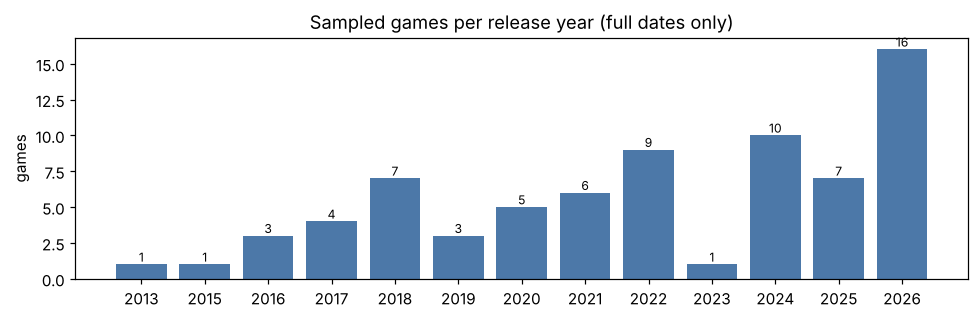

In [4]:
plot = years[years.release_year != "no full date"]
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(plot.release_year, plot.games, color="#4C78A8")
ax.set_title("Sampled games per release year (full dates only)")
ax.set_ylabel("games")
for x, y in zip(plot.release_year, plot.games):
    ax.text(x, y + 0.2, str(y), ha="center", fontsize=8)
plt.tight_layout(); plt.show()

**Finding (I-15).** The sample is 100 games from one landing run (2026-10-03). Years hold 1-16 games:
2013, 2015 and 2023 have **one** game each, so a "year" there is one game, not a trend. 27 games have
no full release date. One retrieval day means `review_snapshot` has no history yet.

## 2. Missing values: what, where, and against what

Missing count and share per column, then each pattern against the fields that might explain it.

In [5]:
cols = ["store_name", "app_type", "is_free", "required_age", "release_date", "release_date_text",
        "coming_soon", "price_currency", "price_initial_cents", "price_final_cents", "discount_percent",
        "platform_windows", "metacritic_score", "recommendations_total"]
detail = q("SELECT * FROM app_detail")
missing = pd.DataFrame({"missing": detail[cols].isna().sum(), "share": detail[cols].isna().mean().round(2)})
missing[missing.missing > 0]

,missing,share
release_date,27,0.27
price_currency,40,0.40
price_initial_cents,40,0.40
price_final_cents,40,0.40
discount_percent,40,0.40
metacritic_score,99,0.99
recommendations_total,91,0.91


In [6]:
# release_date: missing only for unreleased games?
print(pd.crosstab(detail.release_date.isna().map({True: "no full date", False: "full date"}),
                  detail.coming_soon.map({0: "released", 1: "coming soon"})))
print()
# price: missing explained by free / unreleased?
detail["state"] = (detail.is_free.map({1: "free", 0: "paid"}) + " / " +
                   detail.coming_soon.map({1: "coming soon", 0: "released"}))
pd.crosstab(detail.state, detail.price_initial_cents.isna().map({True: "no price", False: "price"}))

coming_soon   coming soon  released
release_date                       
full date               3        70
no full date           27         0



price_initial_cents,no price,price
state,,
free / coming soon,2,0
free / released,10,0
paid / coming soon,28,0
paid / released,0,60


**Findings.** (I-01) every one of the 27 games without a full date is unreleased (`coming_soon = 1`).
(I-03) all 40 missing prices are explained by two observed fields: 12 free games and 28 unreleased paid
games; **0 released paid games lack a price**. Both are missing *because of an observed state*: MAR
given `coming_soon` / `is_free`.

In [7]:
rev = q('''SELECT d.app_key, d.is_free, d.coming_soon, d.release_date, d.recommendations_total,
                  d.metacritic_score, r.total_positive, r.total_negative, r.total_reviews,
                  r.review_score, r.review_score_desc
           FROM app_detail d JOIN review_snapshot r USING (app_key)''')
rev["has_recommendations"] = rev.recommendations_total.notna()
rev.groupby(["is_free", "has_recommendations"]).total_reviews.agg(["count", "min", "median", "max"])

count  min  median    max
is_free has_recommendations                           
0       False                   79    0     2.0    893
        True                     9  149   511.0  19627
1       False                   12    0    39.0    365

**Finding (I-05).** `recommendations_total` exists for 9 apps, all paid, with 149-19,627 reviews.
It is missing for every free game - even ones with 357 and 365 reviews - and for paid games with up to
893 reviews. So it is not a simple "enough reviews" threshold: depends on `is_free` (observed) and on
something we cannot see. `metacritic_score` exists for **1** app (ELEX): critics review mostly bigger
games, so missingness depends on the unobserved critic coverage (MNAR). Neither column can be used.

In [8]:
# review score: missing over time (release year) - Steam writes 0 when it shows no score
rev["year"] = rev.release_date.str[:4].fillna("no full date")
rev["score_state"] = pd.cut(rev.total_reviews, [-1, 0, 9, 10**9], labels=["0 reviews", "1-9 reviews", ">= 10 reviews"])
pd.crosstab(rev.year, rev.score_state, margins=True)

score_state,0 reviews,1-9 reviews,>= 10 reviews,All
year,,,,
2013,0,0,1,1
2015,0,0,1,1
2016,0,0,3,3
2017,0,1,3,4
2018,0,1,6,7
2019,0,1,2,3
2020,0,2,3,5
2021,0,4,2,6
2022,1,5,3,9


**Finding (I-06/I-07).** 58 of 100 apps have fewer than 10 reviews. Their share is highest in recent
years (2021, 2022, 2025, 2026) and among the 27 undated, unreleased games (all 0 reviews). A positive share
by year will describe only the games popular enough to be reviewed - see section 4 of the report.

## 3. Extremes, modes and sentinels

Min, median, max and the most frequent values. Sentinels (0, -1, 999) and impossible values hide here.

In [9]:
num = ["required_age", "price_initial_cents", "price_final_cents", "discount_percent", "metacritic_score",
       "recommendations_total"]
stats = detail[num].describe(percentiles=[0.5]).T[["count", "min", "50%", "max"]]
stats["most frequent"] = [detail[c].value_counts().head(3).to_dict() for c in num]
stats

,count,min,50%,max,most frequent
required_age,100.0,0.0,0.0,16.0,"{0: 99, 16: 1}"
price_initial_cents,60.0,99.0,499.0,3999.0,"{199.0: 11, 499.0: 11, 99.0: 7}"
price_final_cents,60.0,49.0,259.0,2999.0,"{99.0: 7, 199.0: 5, 249.0: 3}"
discount_percent,60.0,0.0,30.0,85.0,"{0.0: 21, 50.0: 9, 30.0: 4}"
metacritic_score,1.0,67.0,67.0,67.0,{67.0: 1}
recommendations_total,9.0,140.0,402.0,12448.0,"{402.0: 1, 8365.0: 1, 12448.0: 1}"


In [10]:
r_num = ["total_positive", "total_negative", "total_reviews", "review_score"]
r_stats = rev[r_num].describe(percentiles=[0.5]).T[["count", "min", "50%", "max"]]
r_stats["most frequent"] = [rev[c].value_counts().head(3).to_dict() for c in r_num]
r_stats

,count,min,50%,max,most frequent
total_positive,100.0,0.0,2.5,14586.0,"{0: 37, 1: 9, 2: 4}"
total_negative,100.0,0.0,1.0,5041.0,"{0: 43, 1: 9, 2: 7}"
total_reviews,100.0,0.0,6.0,19627.0,"{0: 35, 1: 5, 4: 4}"
review_score,100.0,0.0,0.0,8.0,"{0: 58, 8: 12, 5: 12}"


In [11]:
# review_score = 0 is the mode. Is 0 a real score, or a code for "no score"?
print(pd.crosstab(rev.review_score, rev.score_state))
print()
print("review_score_desc where score = 0:",
      sorted(rev[rev.review_score == 0].review_score_desc.unique(), key=lambda s: (len(s), s)))

score_state   0 reviews  1-9 reviews  >= 10 reviews
review_score                                       
0                    35           23              0
3                     0            0              2
4                     0            0              1
5                     0            0             12
6                     0            0              6
7                     0            0              9
8                     0            0             12

review_score_desc where score = 0: ['1 user reviews', '2 user reviews', '3 user reviews', '4 user reviews', '5 user reviews', '6 user reviews', '7 user reviews', '8 user reviews', '9 user reviews', 'No user reviews']


**Finding (I-06, sentinel).** `review_score = 0` for exactly the 58 apps with fewer than 10 reviews, and
for no app with 10 or more (scores 3-8). For them `review_score_desc` is `'No user reviews'` or
`'N user reviews'` - text in place of a rating. So 0 means *no score shown*, not *worst score*: a sentinel.
Cleaning makes it NULL (`missing_no_reviews` / `missing_too_few_reviews`).

`required_age` is 0 for 99 apps and 16 for one; `discount_percent` 0-85; prices 0.99-39.99 USD. No negative
values anywhere (M2's CHECK constraints would reject them).

In [12]:
app = q("SELECT app_key, steam_appid, name, last_modified_at, price_change_number FROM app")
print("app rows:", len(app), "| empty name (NULL):", app.name.isna().sum())
print("last_modified_at:", app.last_modified_at.min(), "..", app.last_modified_at.max())
print("most frequent price_change_number:", app.price_change_number.value_counts().head(3).to_dict())

app rows: 190242 | empty name (NULL): 18
last_modified_at: 2015-11-12T17:55:14Z .. 2026-10-03T11:38:07Z
most frequent price_change_number: {39392500: 62356, 0: 54594, 26388145: 8385}


`price_change_number` = 39,392,500 for 62,356 apps: a global change counter shared by a batch, not a
per-app value. It is not used by the project, so it is documented, not cleaned.

## 4. Distinct values of text and category columns, with `repr()`

Two strings that print the same may not be the same.

In [13]:
for table, id_col in (("genre", "steam_genre_id"), ("category", "steam_category_id")):
    rows = con.execute("SELECT " + id_col + ", description FROM " + table + " ORDER BY 1").fetchall()
    labels = Counter(d for _, d in rows)
    print(table, len(rows), "ids,", len(labels), "distinct labels")
    for i, d in rows:
        mark = "   <- label shared" if labels[d] > 1 else ("   <- not a label" if d.startswith("#") else "")
        if mark or table == "genre":
            print(f"  {i:>3} {d!r}{mark}")

genre 12 ids, 12 distinct labels
    1 'Action'
    2 'Strategy'
    3 'RPG'
    4 'Casual'
    9 'Racing'
   18 'Sports'
   23 'Indie'
   25 'Adventure'
   28 'Simulation'
   29 'Massively Multiplayer'
   37 'Free To Play'
   70 'Early Access'
category 49 ids, 47 distinct labels
   55 'DualShock Controller Support'   <- label shared
   56 'DualShock Controller Support'   <- label shared
   57 'DualSense Controller Support'   <- label shared
   58 'DualSense Controller Support'   <- label shared
   80 '#category_playable_at_your_own_pace'   <- not a label


In [14]:
def apps_with(category_id):
    return {r[0] for r in con.execute(
        "SELECT app_key FROM app_category JOIN category USING (category_key) WHERE steam_category_id = ?",
        (category_id,))}

for a, b in ((55, 56), (57, 58), (74, 80)):
    A, B = apps_with(a), apps_with(b)
    print(f"category {a}: {len(A)} apps | {b}: {len(B)} apps | both: {len(A & B)} | {b} without {a}: {len(B - A)}")

category 55: 8 apps | 56: 5 apps | both: 5 | 56 without 55: 0
category 57: 8 apps | 58: 5 apps | both: 5 | 58 without 57: 0
category 74: 15 apps | 80: 9 apps | both: 9 | 80 without 74: 0


In [15]:
print("release_date_text that is not a full date:")
print(detail[detail.release_date.isna()].release_date_text.map(repr).value_counts().to_string())
print("\nprice_currency:", detail.price_currency.map(repr).value_counts(dropna=False).to_dict())
print("app_type:", detail.app_type.map(repr).value_counts().to_dict())

release_date_text that is not a full date:
release_date_text
'Coming soon'        11
'To be announced'     9
'2026'                3
'2027'                1
'Q4 2026'             1
'October 2026'        1
'November 2026'       1

price_currency: {"'USD'": 60, 'nan': 40}
app_type: {"'game'": 100}


In [16]:
# genre ids that describe a price model or a release state, not gameplay
g = q('''SELECT d.app_key, d.is_free, d.coming_soon, d.release_date, ge.description AS genre
         FROM app_detail d JOIN app_genre USING (app_key) JOIN genre ge USING (genre_key)''')
f2p = set(g[g.genre == "Free To Play"].app_key)
print("Free To Play genre:", len(f2p), "apps; is_free among them:", detail[detail.app_key.isin(f2p)].is_free.tolist())
print("free apps without the genre:", len(set(detail[detail.is_free == 1].app_key) - f2p))
ea = g[g.genre == "Early Access"]
print("Early Access genre:", len(ea), "apps; coming_soon:", ea.coming_soon.tolist(), "; dates:", sorted(ea.release_date))

Free To Play genre: 10 apps; is_free among them: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
free apps without the genre: 2
Early Access genre: 5 apps; coming_soon: [0, 0, 0, 0, 0] ; dates: ['2018-10-15', '2019-08-29', '2021-10-27', '2022-09-05', '2025-06-19']


**Findings.** (I-10) category ids 55/56 and 57/58 share one English label each - and 56 never appears
without 55, 58 never without 57: two ids, one label. (I-11) category 80 arrives as the untranslated
localisation key `'#category_playable_at_your_own_pace'`. (I-12) genre 37 `Free To Play` is a price model
(all 10 apps are free) and genre 70 `Early Access` a release status (all 5 released 2018-2025), not genres.
Release-date texts: `'Coming soon'` 11, `'To be announced'` 9, year only 4, month 2, quarter 1.

## 5. Text and Unicode: do equal things look equal?

In [17]:
names = app.name.dropna()
checks = {
    "not NFC": names.map(lambda s: unicodedata.normalize("NFC", s) != s),
    "leading/trailing whitespace": names.map(lambda s: s != s.strip()),
    "double spaces": names.str.contains("  ", regex=False),
    "control characters (Cc)": names.map(lambda s: any(unicodedata.category(c) == "Cc" for c in s)),
    "non-breaking / ideographic space": names.map(lambda s: "\u00a0" in s or "\u3000" in s),
    "full-width forms (NFKC changes)": names.map(lambda s: unicodedata.normalize("NFKC", s) != s),
    "Turkish letters (İ ı Ş ş Ğ ğ)": names.map(lambda s: any(c in s for c in "İıŞşĞğ")),
}
print(pd.DataFrame({k: [v.sum()] for k, v in checks.items()}, index=["apps"]).T.to_string())
for label in ("not NFC", "control characters (Cc)", "leading/trailing whitespace", "Turkish letters (İ ı Ş ş Ğ ğ)"):
    print(f"\n{label}:", [repr(x) for x in names[checks[label]].head(4)])

                                  apps
not NFC                              2
leading/trailing whitespace        213
double spaces                      270
control characters (Cc)              1
non-breaking / ideographic space     0
full-width forms (NFKC changes)   2564
Turkish letters (İ ı Ş ş Ğ ğ)       27

not NFC: ["'パクっちゃうぞ！！'", "'アッシュエコーズ'"]

control characters (Cc): ["'星塔游戈\\tCelestial Sentinel'"]

leading/trailing whitespace: ["'Disciples II: Rise of the Elves '", "'Iron Warriors: T-72 Tank Command '", "'Ankh 2: Heart of Osiris '", "'Monster Trucks Nitro '"]

Turkish letters (İ ı Ş ş Ğ ğ): ["'Frigus İnferos'", "'HOLY QURAN VR EXPERİENCE'", "'Son Savaşçı'", "'İfrit'"]


In [18]:
# why clean.py does not use .lower() / .casefold() alone for matching Turkish text
for s in ("İfrit", "EXPERİENCE", "Masterpıece"):
    print(f"{s!r:16} lower -> {s.lower()!r:16} casefold -> {s.casefold()!r:16} name_key -> {name_key(s)!r}")
print("\nlen('İ'.lower()) =", len("İ".lower()), "-> 'i' + U+0307 COMBINING DOT ABOVE")

'İfrit'          lower -> 'i̇frit'         casefold -> 'i̇frit'         name_key -> 'ifrit'
'EXPERİENCE'     lower -> 'experi̇ence'    casefold -> 'experi̇ence'    name_key -> 'experience'
'Masterpıece'    lower -> 'masterpıece'    casefold -> 'masterpıece'    name_key -> 'masterpiece'

len('İ'.lower()) = 2 -> 'i' + U+0307 COMBINING DOT ABOVE


In [19]:
sampled = q("SELECT a.steam_appid, a.name AS app_list_name, d.store_name FROM app a JOIN app_detail d USING (app_key)")
diff = sampled[sampled.app_list_name != sampled.store_name]
print("store_name: non-NFC", sum(unicodedata.normalize("NFC", s) != s for s in sampled.store_name),
      "| whitespace issues", sum(s != " ".join(s.split()) for s in sampled.store_name))
diff

store_name: non-NFC 0 | whitespace issues 0


,steam_appid,app_list_name,store_name
61,3073110,怪力乱神:序章,paranormal power:The Prequel
73,3997610,绝对不想BE的愿望攻略法,The Wish Guide Without BE
83,4573370,寻宝猎手Hoard Seeker,Hoard Seeker


**Findings (I-08, I-09).** In the 190,242-name catalogue: 2 names are not NFC, 213 have leading or
trailing spaces, 270 double spaces, 1 contains a tab. These are invisible differences: cleaned by NFC +
whitespace collapse (`text_normalised`). 2,564 names change under NFKC (full-width `＆`, `～`): those are
the title's spelling, so NFKC is used only in the matching key, never in a cleaned name. Turkish letters
appear inside English words (`EXPERİENCE`); `casefold()` turns `İ` into two characters, so the key folds
Turkish letters explicitly. The 100 sampled store names have no text problems; 3 differ from their
catalogue name (native-language title vs English store title) - two attributes, both kept.

## 6. Identity: is one thing recorded as two?

Developer and publisher names (Steam gives them no id), then sampled apps against the whole catalogue.
Matching steps: exact -> normalised key -> fuzzy proposal -> a person decides (`data/mappings/`).

In [20]:
devs = [r[0] for r in con.execute("SELECT name FROM developer")]
pubs = [r[0] for r in con.execute("SELECT name FROM publisher")]
print("exact: publisher names that are also developer names:", len(set(devs) & set(pubs)), "of", len(pubs))

names = [("developer", n) for n in devs] + [("publisher", n) for n in pubs]
keyed = [(r, n, name_key(n)) for r, n in names]
same_key = [(a, b) for i, a in enumerate(keyed) for b in keyed[i + 1:] if a[1] != b[1] and a[2] == b[2]]
print("\nnormalised key: different names, same key")
for a, b in same_key:
    print(f"  {a[0]:9} {a[1]!r:22} {b[0]:9} {b[1]!r:22} key {a[2]!r}")

exact: publisher names that are also developer names: 79 of 101

normalised key: different names, same key
  developer 'Jesse Carradine'      publisher 'Jesse Carradine?'     key 'jessecarradine'
  developer 'Relaxygen Studios'    publisher 'Relaxygen studios'    key 'relaxygenstudios'


In [21]:
# fuzzy proposals at several cutoffs (on the key)
def fuzzy(cutoff, key=name_key):
    out = []
    for i, (ra, a) in enumerate(names):
        for rb, b in names[i + 1:]:
            ka, kb = key(a), key(b)
            if a != b and ka and kb and ka != kb:
                r = difflib.SequenceMatcher(None, ka, kb).ratio()
                if r >= cutoff:
                    out.append((round(r, 3), f"{ra} {a!r}", f"{rb} {b!r}"))
    return sorted(out, reverse=True)

for cutoff in (0.75, 0.80, 0.85):
    found = fuzzy(cutoff)
    print(f"cutoff {cutoff}: {len(found)} proposal(s)")
    for p in found:
        print("   ", p)

cutoff 0.75: 8 proposal(s)
    (0.812, "developer 'KPP Entertainment'", "publisher 'BFG Entertainment'")
    (0.8, "developer 'KPP Entertainment'", "publisher 'Novark Entertainment'")
    (0.8, "developer 'KPP Entertainment'", "developer 'Novark Entertainment'")
    (0.78, "developer 'Novark Entertainment'", "publisher 'Forever Entertainment S. A.'")
    (0.762, "publisher 'Hakuto Games'", "publisher 'baKno Games'")
    (0.762, "developer 'baKno Games'", "publisher 'Hakuto Games'")
    (0.762, "developer 'Hakuto Games'", "publisher 'baKno Games'")
    (0.762, "developer 'Hakuto Games'", "developer 'baKno Games'")
cutoff 0.8: 3 proposal(s)
    (0.812, "developer 'KPP Entertainment'", "publisher 'BFG Entertainment'")
    (0.8, "developer 'KPP Entertainment'", "publisher 'Novark Entertainment'")
    (0.8, "developer 'KPP Entertainment'", "developer 'Novark Entertainment'")
cutoff 0.85: 0 proposal(s)


In [22]:
# a first attempt kept only ASCII letters in the key: two different Chinese studios then get the same key
ascii_key = lambda s: "".join(c for c in unicodedata.normalize("NFKC", s).casefold() if c.isascii() and c.isalnum())
for studio in ("本格工作室", "虚一工作室"):
    print(f"{studio}: ascii key {ascii_key(studio)!r:4} | name_key {name_key(studio)!r}")
print("same key under the ASCII-only version:", ascii_key("本格工作室") == ascii_key("虚一工作室"))

本格工作室: ascii key ''   | name_key '本格工作室'
虚一工作室: ascii key ''   | name_key '虚一工作室'
same key under the ASCII-only version: True


**Findings (I-13).** Exact: 79 of 101 publisher names are also developer names (self-published).
Normalised key: `'Relaxygen studios'` / `'Relaxygen Studios'` and `'Jesse Carradine?'` / `'Jesse Carradine'`,
each credited on the **same app** as developer and publisher: one company each. Fuzzy at 0.80 proposes
3 pairs that share only the word *Entertainment*: a person rejected all 3. An ASCII-only key would have
given the two Chinese studios `本格工作室` and `虚一工作室` the same key `''`, so the normalised-key step
would have called them one company: `name_key` keeps every Unicode letter, and an empty key never matches.

In [23]:
catalogue = defaultdict(list)
for appid, n in app[["steam_appid", "name"]].itertuples(index=False):
    k = name_key(normalise_text(n)) if isinstance(n, str) else None
    if k:
        catalogue[k].append((appid, n))
print("catalogue name keys shared by more than one appid:", sum(len(v) > 1 for v in catalogue.values()))
print("names with no letter or digit (key None, never matched):",
      [n for n in app.name.dropna() if name_key(n) is None][:8])
pairs = []
for appid, a_name, s_name in sampled.itertuples(index=False):
    for k in {name_key(a_name), name_key(s_name)} - {None}:
        pairs += [(appid, a_name, other, o_name) for other, o_name in catalogue[k] if other != appid]
pd.DataFrame(pairs, columns=["sampled_appid", "sampled_name", "other_appid", "other_name"]).merge(
    app[["steam_appid", "last_modified_at"]].rename(columns={"steam_appid": "other_appid",
                                                          "last_modified_at": "other_last_modified"}))

catalogue name keys shared by more than one appid: 3242
names with no letter or digit (key None, never matched): ['※', '***', '-', '-', '.', '∞', '∆', '-']


,sampled_appid,sampled_name,other_appid,other_name,other_last_modified
0,803310,Landlord Simulator,4168700,Landlord Simulator,2026-10-01T17:02:57Z
1,1364500,Drive or Die,4930190,Drive or Die,2026-09-21T19:00:11Z
2,1412620,Sweet Time,4618290,Sweet Time,2026-07-23T20:15:15Z
3,1548050,Presence,2063720,Presence,2023-11-14T17:27:00Z
4,1548050,Presence,2378990,Presence,2024-03-20T20:45:34Z
5,1721100,CURSES,3710830,Curses,2025-10-15T18:38:49Z
6,3077710,Dice,1278860,Di[c]E,2025-08-22T02:32:18Z
7,3077710,Dice,4940860,Dice,2026-09-22T13:04:46Z
8,5079930,Monster Collector,1423090,Monster Collector,2021-02-19T15:56:25Z


**Finding (I-14).** 7 sampled games share a name key with 9 other catalogue apps (generic titles:
*Presence*, *Dice*, *Monster Collector*). The other apps were not sampled, so there is no store page,
developer or release date to compare: the cause is **unknown**. They stay separate
(`data/mappings/app_identity.csv`); because the other apps have no rows in `app_detail` or
`review_snapshot`, no per-app statistic changes either way.

## 7. Values in sequence

There is one snapshot per app, so stuck values or level shifts over time cannot exist yet. The sequence
we do have is the **appid**, which Steam hands out in increasing order: a game re-registered under a new
appid would show up as a high appid with an old release date.

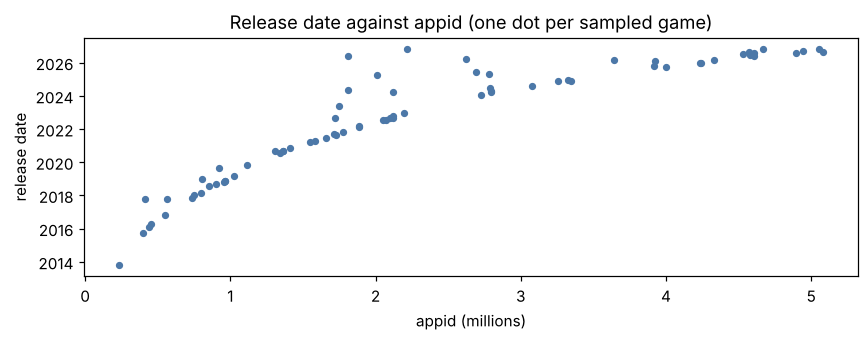

,count,min,max,drop_years
band,,,,
0.0,5,2013-10-14,2017-10-17,NaN
0.5,12,2016-10-27,2019-08-29,-3.0
1.0,7,2019-02-27,2020-11-19,-2.3
1.5,12,2021-03-24,2026-05-20,-2.1
2.0,9,2022-07-27,2026-11-03,-1.3
2.5,7,2024-01-10,2026-03-26,-1.5
3.0,4,2024-08-10,2024-12-20,-0.6
3.5,4,2025-09-26,2026-03-03,-1.1
4.0,3,2025-12-25,2026-02-19,-0.2


In [24]:
seq = q('''SELECT a.steam_appid, d.release_date FROM app_detail d JOIN app a USING (app_key)
           WHERE d.release_date IS NOT NULL ORDER BY a.steam_appid''')
seq["release_date"] = pd.to_datetime(seq.release_date)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.scatter(seq.steam_appid / 1e6, seq.release_date, s=14, color="#4C78A8")
ax.set_xlabel("appid (millions)"); ax.set_ylabel("release date")
ax.set_title("Release date against appid (one dot per sampled game)")
plt.tight_layout(); plt.show()

seq["band"] = (seq.steam_appid // 500_000) * 0.5
bands = seq.groupby("band").release_date.agg(["count", "min", "max"])
# positive = this band's earliest game is OLDER than the earliest game of an earlier (lower-appid) band
bands["drop_years"] = (bands["min"].cummax().shift() - bands["min"]).dt.days.div(365).round(1)
bands

**Finding (checked, nothing found).** The earliest release date per 500,000-appid band never goes
back in time (`drop_years` is never positive), so no sampled game looks like an old game re-registered
under a new appid. Games released long after their appid (e.g. appid 2,011,240 released
2025) are long developments, which is normal.

## 8. Unusual values: robust fences, and what they flag

Review counts and prices span orders of magnitude. Mean +/- 3 SD is distorted by the very values it looks for,
so we compare IQR fences on the raw scale and on log10, and look at what each one flags.

In [25]:
def fence(values, k=1.5):
    s = pd.Series(values, dtype=float)
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return q3 + k * (q3 - q1)

def robust_z(values):
    s = pd.Series(values, dtype=float); med = s.median(); mad = (s - med).abs().median()
    return 0.6745 * (s - med) / mad

reviews = rev[rev.total_reviews > 0].set_index(rev[rev.total_reviews > 0].app_key).total_reviews
raw_fence, log_fence = fence(reviews), 10 ** fence(reviews.map(math.log10))
mean_3sd = reviews.mean() + 3 * reviews.std()
print(f"total_reviews > 0: n = {len(reviews)}, median {reviews.median():.0f}, max {reviews.max():,}")
print(f"  raw IQR fence   {raw_fence:>8,.0f} -> flags {(reviews > raw_fence).sum()} apps")
print(f"  log10 IQR fence {log_fence:>8,.0f} -> flags {(reviews > log_fence).sum()} apps")
print(f"  robust z (log) > 3.5          -> flags {(robust_z(reviews.map(math.log10)) > 3.5).sum()} apps")
print(f"  mean + 3 SD     {mean_3sd:>8,.0f} -> flags {(reviews > mean_3sd).sum()} apps (not used)")
names_by_key = dict(detail[["app_key", "store_name"]].itertuples(index=False))
print("\nflagged by the log10 fence:", [(names_by_key[k], int(v)) for k, v in reviews[reviews > log_fence].items()])

total_reviews > 0: n = 65, median 23, max 19,627
  raw IQR fence        222 -> flags 11 apps
  log10 IQR fence    4,504 -> flags 3 apps
  robust z (log) > 3.5          -> flags 0 apps
  mean + 3 SD        9,181 -> flags 2 apps (not used)

flagged by the log10 fence: [('Timberman', 11158), ('ELEX', 19627), ('Life is Strange: Reunion', 5747)]


price_initial_cents: n = 60, median 499, max 3999
  raw IQR fence     2199 -> flags 3: [2499, 2999, 3999]
  log10 IQR fence  11237 -> flags 0


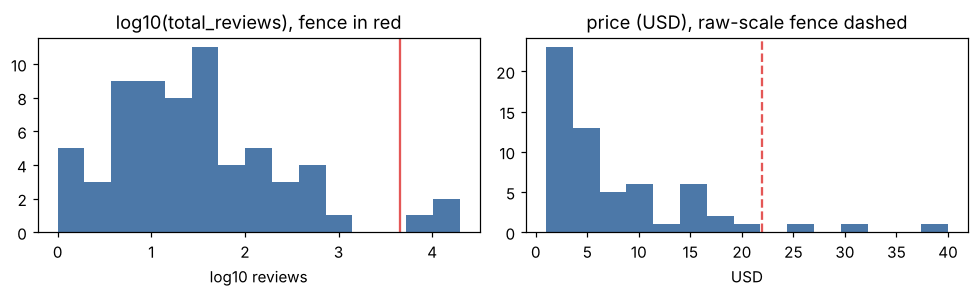

In [26]:
prices = detail.price_initial_cents.dropna()
print(f"price_initial_cents: n = {len(prices)}, median {prices.median():.0f}, max {prices.max():.0f}")
print(f"  raw IQR fence   {fence(prices):>6.0f} -> flags {(prices > fence(prices)).sum()}: "
      f"{sorted(prices[prices > fence(prices)].astype(int))}")
print(f"  log10 IQR fence {10 ** fence(prices.map(math.log10)):>6.0f} -> flags {(prices > 10 ** fence(prices.map(math.log10))).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
axes[0].hist(reviews.map(math.log10), bins=15, color="#4C78A8"); axes[0].axvline(math.log10(log_fence), color="#E45756")
axes[0].set_title("log10(total_reviews), fence in red"); axes[0].set_xlabel("log10 reviews")
axes[1].hist(prices / 100, bins=15, color="#4C78A8"); axes[1].axvline(fence(prices) / 100, color="#E45756", ls="--")
axes[1].set_title("price (USD), raw-scale fence dashed"); axes[1].set_xlabel("USD")
plt.tight_layout(); plt.show()

**Findings (I-16).** On the raw scale the review fence (222) flags 11 of 65 apps - a sixth of the data;
mean + 3 SD flags 2. On log10 the IQR fence (about 4,500 reviews) flags 3: **ELEX (19,627), Timberman (11,158),
Life is Strange: Reunion (5,747)** - three well-known games, real popularity, not errors. They are flagged
`unusual_high` and **kept**. For prices, the raw fence flags normal full-game prices (24.99-39.99 USD); the
log10 fence flags nothing. One global fence is used because every app has a single value (no per-app history).

## 9. Rules across fields

In [27]:
priced = detail[detail.price_initial_cents.notna()]
expected = priced.price_initial_cents * (100 - priced.discount_percent) / 100
gap = (priced.price_final_cents - expected)
bands = {1: (0, 20), 2: (0, 20), 3: (0, 20), 4: (20, 40), 5: (40, 70), 6: (70, 80), 7: (80, 101), 8: (80, 101), 9: (95, 101)}
scored = rev[rev.total_reviews >= 10].copy()
scored["share"] = 100 * scored.total_positive / scored.total_reviews
scored["in_band"] = [bands[s][0] <= sh < bands[s][1] for s, sh in zip(scored.review_score, scored.share)]
retrieved_day = detail.retrieved_at.str[:10]
rules = {
    "positive + negative <> total": int((rev.total_positive + rev.total_negative != rev.total_reviews).sum()),
    "final price > initial price": int((priced.price_final_cents > priced.price_initial_cents).sum()),
    "max |final - initial*(1-discount)| (cents)": round(float(gap.abs().max()), 2),
    "discount = 0 but final <> initial": int(((priced.discount_percent == 0) & (priced.price_final_cents != priced.price_initial_cents)).sum()),
    "is_free = 1 but a price is given": int(((detail.is_free == 1) & detail.price_initial_cents.notna()).sum()),
    "currency other than USD": int((priced.price_currency != "USD").sum()),
    "score label outside its share band (>= 10 reviews)": int((~scored.in_band).sum()),
    "recommendations_total > total_reviews": int((rev.recommendations_total > rev.total_reviews).sum()),
    "released (coming_soon = 0) with a date after retrieval": int(((detail.coming_soon == 0) & (detail.release_date > retrieved_day)).sum()),
    "coming soon with a date before retrieval": int(((detail.coming_soon == 1) & (detail.release_date <= retrieved_day)).sum()),
    "coming soon with a full date after retrieval (announced)": int(((detail.coming_soon == 1) & (detail.release_date > retrieved_day)).sum()),
    "unreleased game with reviews": int(((rev.coming_soon == 1) & (rev.total_reviews > 0)).sum()),
}
pd.Series(rules, name="rows").to_frame()

,rows
positive + negative <> total,0.00
final price > initial price,0.00
max |final - initial*(1-discount)| (cents),0.85
discount = 0 but final <> initial,0.00
is_free = 1 but a price is given,0.00
currency other than USD,0.00
score label outside its share band (>= 10 reviews),0.00
recommendations_total > total_reviews,0.00
released (coming_soon = 0) with a date after retrieval,0.00
coming soon with a date before retrieval,0.00


In [28]:
r9 = rev[rev.recommendations_total.notna()]
(r9.recommendations_total / r9.total_reviews).describe()[["count", "min", "50%", "max"]].round(2)

count    9.00
min      0.63
50%      0.86
max      0.94
dtype: float64

**Findings.** Every cross-field rule holds: counts add up, discounts match to within one cent (Steam rounds
down: 599 x 25 % = 149.75 -> 149), every score label sits inside its share band, no released game is dated in
the future. 3 unreleased games have announced dates after retrieval (I-02) - consistent with `coming_soon`.
(I-17) `recommendations_total` is 63-94 % of `total_reviews` for the 9 apps that have it: our counts
include key activations (`purchase_type=all`), while Steam counts only Steam purchases toward its score.

## 10. Findings -> issues register

| Issue | Finding | Section |
|---|---|---|
| I-01 | 27 games without a full release date, all unreleased (20 not announced, 7 partial) | 2, 4 |
| I-02 | 3 announced release dates after the retrieval day (coming soon) | 9 |
| I-03 | 40 missing prices: 12 free, 28 unreleased paid, 0 unexplained | 2 |
| I-04 | `metacritic_score` missing for 99 of 100 | 2 |
| I-05 | `recommendations_total` missing for 91 of 100, all free games among them | 2 |
| I-06 | `review_score = 0` sentinel for the 58 apps with < 10 reviews | 3 |
| I-07 | 35 apps with 0 reviews - a real zero, concentrated in unreleased and recent games | 2 |
| I-08 | 477 catalogue names with invisible text differences (NFC, whitespace, tab) | 5 |
| I-09 | 18 catalogue apps with an empty name | 3 |
| I-10 | categories 55/56 and 57/58 share a label | 4 |
| I-11 | category 80 label is an untranslated localisation key | 4 |
| I-12 | genres 37 and 70 are a price model and a release status | 4 |
| I-13 | 2 publisher names are spellings of a developer on the same app; 3 fuzzy false positives | 6 |
| I-14 | 7 sampled games share a name with 9 other catalogue apps | 6 |
| I-15 | 1-16 games per year, one retrieval run | 1 |
| I-16 | 3 apps with unusually many reviews (kept) | 8 |
| I-17 | `recommendations_total` < `total_reviews` (different scope) | 9 |

In [29]:
con.close()